# Solving the n-Queens Problem using Local Search

Student Name: [Truong Thi Huyen Trang, Le Thi Thuy Tien]

I have used the following AI tools: [list tools]

I understand that my submission needs to be my own work: [your initials]


## Learning Outcomes

* Implement multiple `hill climbing` search variants to solve the `n-Queens` problem.
(triển khai các biến thể của `thuật toán tìm kiếm leo đồi` để giải quyết bài toán `n-Queens`)

* Apply `simulated annealing` with `appropriate temperature scheduling` to overcome local optima.
(Áp dụng `luyện kim mô phỏng` với `lịch trình điều chỉnh nhiệt độ` phù hơp để vượt qua các cực trị địa phương.)

* Compare algorithm performance using `runtime`, `solution quality`, and `success rate metrics`.
(So sánh hiệu năng của thuật toán dựa trên thời gian chạy, chất lượng lời giải, các đánh giá mức độ thành công.)

* Analyze and visualize algorithm performance across different problem sizes.
(Phân tích và trực quan hóa hiệu năng của bằng toán thông qua các kích thước khác nhau của bài toán)

* Graduate Students: Design and test `alternative local move operators` to improve search efficiency.
(Thiết kế và kiểm tra các `toán tử di chuyển địa phương thay thế` nhằm cải thiện hiệu suất tìm kiếm)


## Instructions

Total Points: Undergrads 100 + 5 bonus / Graduate students 110

Complete this notebook. Use the provided notebook cells and insert additional code and markdown cells as needed. Submit the completely rendered notebook as a HTML file. 

In [173]:
# change directory to Google Drive for Google Colab
try:
    from google.colab import drive
    import os

    drive.mount('/content/drive')
    os.chdir('/content/drive/My Drive/Colab Notebooks/')
    print("Your working directory is now Google Drive: My Drive > Colab Notebooks")
except ImportError:
    pass

## The n-Queens Problem

* __Goal:__ Find an arrangement of $n$ queens on a $n \times n$ chess board so that no queen is on the same row, column or diagonal as any other queen.
- (__Mục tiêu__: Sắp xép các n-hậu trên bàn cờ vua sao cho không có quân hậu nào `cùng hàng, cột hoặc đường chéo` với quân hậu khác.)

* __State space:__ An arrangement of the queens on the board. We restrict the state space to arrangements where there is only a single queen per column. We represent a state as an integer vector $\mathbf{q} = \{q_1, q_2, \dots, q_n\}$, each number representing the row positions of the queens from left to right. We will call a state a "board."
- (__Không gian trạng thái__: một sự sắp xếp của các quân hậu trên bàn cờ. Chúng ta giới hạn không gian trạng thái để sắp xếp mà nơi đó `chỉ có 1 quân hậu trên cột`. Chúng ta biểu diễn 1 trạng thái dưới dạng vector số nguyên $\mathbf{q} = \{q_1, q_2, \dots, q_n\}$, `mỗi số biểu diễn vị vi trí hàng` của các quân hậu từ trái sang phải.)

* __Objective function:__ The number of pairwise conflicts (i.e., two queens in the same row/column/diagonal).
The optimization problem is to find the optimal arrangement $\mathbf{q}^*$ of $n$ queens on the board can be written as:
- (__Hàm mục tiêu__: Số lượng các cặp xung đột nhau (nghĩa là 2 quân hậu `cùng hàng/cột/đường chéo`). Vấn đề tối ưu hóa là tìm ra sự sắp xếp tối ưu $\mathbf{q}^*$ của $n$ quân hậu trên bào cờ được viết như sau:)


  > minimize: $\mathrm{conflicts}(\mathbf{q})$ (cực tiểu hóa)
  >
  > subject to: $\mathbf{q} \ \text{contains only one queen per column}$ (với điều kiện q\chỉ chứa 1 quân hậu trên 1 cột)

  Note: the constraint (subject to) is enforced by the definition of the state space.
  - (Chú ý: Ràng buộc này được đảm bảo thông qua định nghĩa về không gian trạng thái.)

* __Local improvement move:__ Move one queen to a different row in its column.
-( __Di chuyển cải thiện địa phương__: di chuyển 1 quan hậu sang 1 hàng khác của chính (cùng) cột đó.)

* __Termination:__ For this problem there is always an arrangement $\mathbf{q}^*$ with $\mathrm{conflicts}(\mathbf{q}^*) = 0$, however, the local improvement moves might end up in a local minimum. 
- (__Kết thúc__: Với vấn đề này, luôn xuất hiện một sự sắp xếp $\mathbf{q}^*$ with $\mathrm{conflicts}(\mathbf{q}^*) = 0$, tuy nhiên, các bước cải thiện cục bộ có thể dẫn đến một cực tiểu cực bộ.)

## Helper functions

Cell code dưới này, có tổng 4 hàm def: 
- random_board(n) : tạo ngẫu nhiên các quân hậu theo, input = n. Ex: n = 4 => n-Queens = 4x4 bàn cờ
- comb2(n): ở hàm này dùng tổ hợp chập 2 của n. với n là số quân hậu => hàm comb sẽ trả lại số cặp quân hậu. ví dụ 3 quân hậu thì có 3 cặp quân, 4 quân hậu => 6 cặp quân.
- conflicts(board) : tính các cặp quân hậu ăn nhau, còn gọi là số cặp quân hậu xung đột
- show_board(board, col, fontsize): in bàn cờ ra 

In [174]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib import colors

np.random.seed(1234)


def random_board(n):
    """Creates a random board of size n x n. Note that only a single queen is placed in each column!"""
    
    return(np.random.randint(0,n, size = n))

def comb2(n): return n*(n-1)//2 # this is n choose 2 equivalent to math.comb(n, 2); // is int division

def conflicts(board):
    """Calculate the number of conflicts, i.e., the objective function."""

    n = len(board) 
    
    #khởi tạo các đường ngang, đường chéo 1 và 2 ban đầu = 0
    #không có đếm theo cột, vì định sẵn mỗi cột là 1 quân hậu => xung đột sẽ diễn ra theo hàng ngang, đường chéo.
    horizontal_cnt = [0] * n
    diagonal1_cnt = [0] * 2 * n
    diagonal2_cnt = [0] * 2 * n
    
    #Với mỗi quân hậu, đếm số hàng và đường chéo 1 và 2 mà nó chiếm.
    for i in range(n):
        horizontal_cnt[board[i]] += 1
        diagonal1_cnt[i + board[i]] += 1
        diagonal2_cnt[i - board[i] + n] += 1
    
    return sum(map(comb2, horizontal_cnt + diagonal1_cnt + diagonal2_cnt))
    # horizontal_cnt + diagonal1_cnt + diagonal2_cnt: nối 3 list lại thành 1 list dài
    

# decrease the font size to fit larger boards
def show_board(board, cols = ['white', 'gray'], fontsize = 48):  
    """display the board"""
    
    n = len(board)
    
    # create chess board display
    display = np.zeros([n,n])
    for i in range(n):
        for j in range(n):
            if (((i+j) % 2) != 0): 
                display[i,j] = 1
    
    cmap = colors.ListedColormap(cols)
    fig, ax = plt.subplots()
    ax.imshow(display, cmap = cmap, 
              norm = colors.BoundaryNorm(range(len(cols)+1), cmap.N))
    ax.set_xticks([])
    ax.set_yticks([])
    
    # place queens. Note: Unicode u265B is a black queen
    for j in range(n):
        plt.text(j, board[j], u"\u265B", fontsize = fontsize, 
                 horizontalalignment = 'center',
                 verticalalignment = 'center')
    
    print(f"Board with {conflicts(board)} conflicts.")
    plt.show()

## Create a board

Board with 4 conflicts.


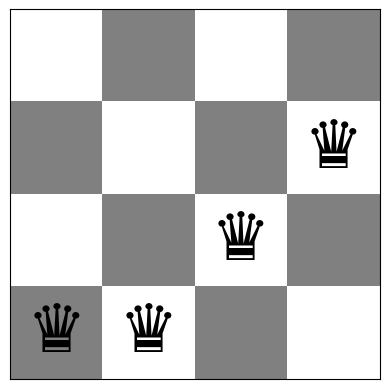

length of board: 4
Queens (left to right) are at rows: [3 3 2 1]
Number of conflicts: 4


In [175]:
board = random_board(4)

show_board(board)
print(f"length of board: {len(board)}")
print(f"Queens (left to right) are at rows: {board}")
print(f"Number of conflicts: {conflicts(board)}")

A board $4 \times 4$ with no conflicts:

Board with 0 conflicts.


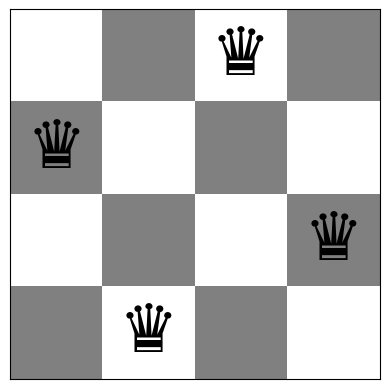

In [176]:
board = [1,3,0,2]
show_board(board)

#### __Biểu diễn trạng thái bằng vector có n phần tử; mỗi cột đặt đúng một quân hậu, giá trị của phần tử là chỉ số hàng.__

Trạng thái được biểu diễn bằng vector $\mathbf{q} = (q_0, q_1, \dots, q_{n-1})$:
- Chỉ số $i$ là **số cột**, giá trị $q_i$ là **số hàng** của quân hậu ở cột $i$.
- Mỗi cột chỉ có một phần tử, nên mỗi cột luôn có đúng một quân hậu. Ràng buộc "một hậu mỗi cột" được đảm bảo ngay trong cách biểu diễn.
- Không gian trạng thái có $n^n$ trạng thái. Ví dụ $n = 8$ có $8^8 \approx 16{,}7$ triệu trạng thái, ít hơn nhiều so với $C(64, 8) \approx 4{,}4$ tỷ nếu đặt hậu tùy ý.

**Hàm mục tiêu:** $f(\mathbf{q}) = \mathrm{conflicts}(\mathbf{q})$ là số cặp quân hậu tấn công nhau (cùng hàng hoặc cùng đường chéo).

**Mục tiêu:** $\min f(\mathbf{q})$. Lời giải hợp lệ khi $f(\mathbf{q}) = 0$.



#### __Xác định phép di chuyển cục bộ chuyển một quân hậu sang hàng khác trong cùng cột, đếm số trạng thái láng giềng.__

In [177]:
def neighbors(board):
    """Sinh tất cả trạng thái láng giềng: chuyển 1 quân hậu sang hàng khác trong cùng cột."""
    board = np.array(board)
    n = len(board)
    result = []
    for col in range(n):
        for row in range(n):
            if row != board[col]:          # bỏ qua hàng hiện tại
                nb = board.copy()
                nb[col] = row
                result.append(nb)
    return result

for n in [4, 8]:
    board = random_board(n)
    print(f"n = {n}: số láng giềng = {len(neighbors(board))}, công thức n(n-1) = {n*(n-1)}")

n = 4: số láng giềng = 12, công thức n(n-1) = 12
n = 8: số láng giềng = 56, công thức n(n-1) = 56


Phép di chuyển cục bộ: chọn một cột $i$ và chuyển quân hậu sang một hàng khác trong cùng cột, tức là đổi giá trị $q_i$.

Mỗi cột có $n - 1$ hàng khác để chuyển tới, và có $n$ cột. Vậy mỗi trạng thái có $n(n-1)$ láng giềng:
- $n = 4$: $4 \times 3 = 12$ láng giềng
- $n = 8$: $8 \times 7 = 56$ láng giềng

n = 4, vector trạng thái: [0 0 2 2]
Quân hậu ở cột 0 đang ở hàng 0
Quân hậu ở cột 1 đang ở hàng 0
Quân hậu ở cột 2 đang ở hàng 2
Quân hậu ở cột 3 đang ở hàng 2
Board with 4 conflicts.


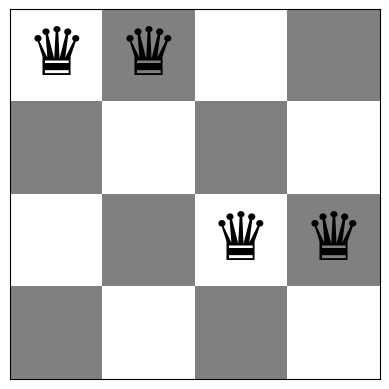

n = 8, vector trạng thái: [2 0 0 4 5 0 1 7]
Quân hậu ở cột 0 đang ở hàng 2
Quân hậu ở cột 1 đang ở hàng 0
Quân hậu ở cột 2 đang ở hàng 0
Quân hậu ở cột 3 đang ở hàng 4
Quân hậu ở cột 4 đang ở hàng 5
Quân hậu ở cột 5 đang ở hàng 0
Quân hậu ở cột 6 đang ở hàng 1
Quân hậu ở cột 7 đang ở hàng 7
Board with 7 conflicts.


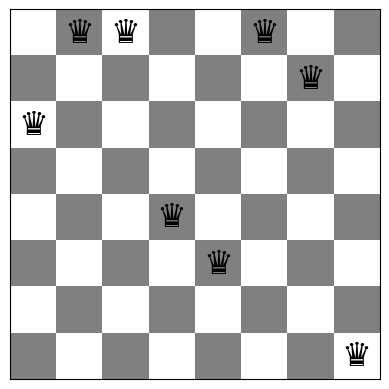

In [178]:
for n in [4, 8]:
    board = random_board(n)
    print(f"n = {n}, vector trạng thái: {board}")
    for i in range(n):
        print(f"Quân hậu ở cột {i} đang ở hàng {board[i]}")
    show_board(board, cols = ['white', 'gray'], fontsize = 48 if n == 4 else 24)

#### __Thực hiện trên n = 4 và n = 8; so sánh bàn cờ ngẫu nhiên với cấu hình [1, 3, 0, 2] (n = 4).__

In [179]:
def compare(board, name):
    nbs = neighbors(board)
    c = conflicts(board)
    better = sum(1 for nb in nbs if conflicts(nb) < c)
    print(f"{name}: {np.array(board)} | conflicts = {c} | "
          f"số láng giềng tốt hơn = {better}/{len(nbs)}")

compare(random_board(4), "Bàn cờ ngẫu nhiên")
compare([1, 3, 0, 2], "Cấu hình [1,3,0,2]")

Bàn cờ ngẫu nhiên: [2 2 3 2] | conflicts = 5 | số láng giềng tốt hơn = 8/12
Cấu hình [1,3,0,2]: [1 3 0 2] | conflicts = 0 | số láng giềng tốt hơn = 0/12


**Nhận xét:**
- Bàn cờ ngẫu nhiên thường có xung đột > 0 và có láng giềng tốt hơn. `Thuật toán leo đồi` có thể đi tiếp từ trạng thái này để giảm xung đột.
- Cấu hình [1, 3, 0, 2] có 0 xung đột, là **lời giải tối ưu toàn cục**. Không láng giềng nào tốt hơn, vì bất kỳ di chuyển nào cũng tạo ra xung đột mới.
- Với n = 8, bàn cờ ngẫu nhiên thường có nhiều xung đột hơn, vì nhiều quân hậu hơn thì nhiều cặp có khả năng tấn công nhau hơn.


# Tasks

## General [10 Points]

1. Make sure that you use the latest version of this notebook. Sync your forked repository and pull the latest revision. 

2. Your implementation can use libraries like math, numpy, scipy, but not libraries that implement intelligent agents or complete search algorithms. Try to keep the code simple! In this course, we want to learn about the algorithms and we often do not need to use object-oriented design.
* (Bạn có thể sử dụng các thư viện như `math`, `numpy`, `scipy`, nhưng không được phép sử dụng các thư viện đã tích hợp sẵn các tác nhân thông minh (intelligent agents) hoặc các thuật toán tìm kiếm hoàn chỉnh. Hãy cố gắng giữ cho mã nguồn đơn giản! Trong khóa học này, mục tiêu là tìm hiểu về các thuật toán, vì vậy thường không cần thiết phải sử dụng thiết kế hướng đối tượng.)

3. You notebook needs to be formatted professionally. 
    - Add additional markdown blocks for your description, comments in the code, add tables and use mathplotlib to produce charts where appropriate
    - Do not show debugging output or include an excessive amount of output.
    - Check that your submitted file is readable and contains all figures.
* (Notebook của bạn cần được trình bày một cách chuyên nghiệp.
    - Bổ sung các khối markdown để giải thích nội dung, thêm chú thích vào mã nguồn, sử dụng bảng biểu và dùng `matplotlib` để tạo biểu đồ khi cần thiết.
    - Không hiển thị các thông tin gỡ lỗi (debugging output) hoặc các kết quả đầu ra không cần thiết với số lượng quá lớn.
    - Kiểm tra để đảm bảo tệp tin nộp bài có thể đọc được và chứa đầy đủ các hình ảnh/biểu đồ.)

4. Document your code. Use comments in the code and add a discussion of how your implementation works and your design choices.
* (Ghi chú cho mã nguồn của bạn. Hãy thêm các chú thích trong mã nguồn, đồng thời giải thích cách thức hoạt động của chương trình và lý do cho các lựa chọn thiết kế mà bạn đã thực hiện.)

## Task 1: Steepest-ascend Hill Climbing Search [20 Points] (Tìm kiếm leo đồi theo hướng dốc nhất)

Calculate the objective function for all local moves (see definition of local moves above) and always choose the best among all local moves. If there are no local moves that improve the objective, then you have reached a local optimum. 

- (Tính toán hàm mục tiêu cho tất cả các bước di chuyển cục bộ (xem định nghĩa về các bước di chuyển cục bộ ở trên) và luôn chọn bước di chuyển tốt nhất trong số đó. Nếu không có bước di chuyển cục bộ nào giúp cải thiện hàm mục tiêu, thì bạn đã đạt đến một cực trị cục bộ (local optimum).)

### Mô tả thuật toán
1. Bắt đầu từ bàn cờ cho trước, tính số xung đột hiện tại.
2. Mỗi bước: sinh toàn bộ $n(n-1)$ láng giềng bằng `neighbors`, tính `conflicts` cho từng láng giềng và chọn láng giềng có ít xung đột nhất.
3. Nếu láng giềng tốt nhất **tốt hơn hẳn** trạng thái hiện tại thì di chuyển sang đó. Nếu không thì dừng: đã đến cực tiểu cục bộ, hoặc đã đạt 0 xung đột.

**Lựa chọn thiết kế:**
- Chỉ nhận láng giềng tốt hơn hẳn (`<`), nên thuật toán dừng khi gặp vùng bằng phẳng và không lặp vô hạn.
- Khi nhiều láng giềng cùng tốt nhất, chọn láng giềng gặp đầu tiên, nên thuật toán tất định.
- `max_steps` bảo đảm thuật toán luôn dừng.
- Hàm trả về `history` (số xung đột qua từng bước) và `path` (bàn cờ qua từng bước) để minh họa và phân tích hội tụ.
- Chi phí mỗi bước: $n(n-1)$ lần gọi `conflicts`, mỗi lần $O(n)$, tức $O(n^3)$.

In [180]:
def hill_climb(board, max_steps=1000):
    """
    Steepest-ascent Hill Climbing cho bài toán n-Queens.
    Trả về: (bàn cờ cuối, số xung đột cuối, lịch sử số xung đột, danh sách bàn cờ qua từng bước)
    """
    current_state = np.array(board)
    current_c = conflicts(current_state)
    history = [current_c]
    path = [current_state.copy()]               # lưu bàn cờ ban đầu

    for step in range(max_steps):
        # Duyệt toàn bộ láng giềng, tìm láng giềng có ít xung đột nhất
        best, best_c = current_state, current_c
        for i in neighbors(current_state):
            c = conflicts(i)
            if c < best_c:
                best, best_c = i, c

        # Không có láng giềng nào tốt hơn → cực tiểu cục bộ (hoặc đã đạt 0) → dừng
        if best_c >= current_c:
            break

        current_state, current_c = best, best_c
        history.append(current_c)
        path.append(current_state.copy())       # lưu bàn cờ sau mỗi bước

    return current_state, current_c, history, path

In [181]:
def show_move(prev, cur, step, fontsize=48 if n == 4 else 28):
    """Vẽ bàn cờ sau một bước: quân hậu vừa di chuyển tô đỏ, vị trí cũ hiện mờ."""
    n = len(cur)
    col = np.flatnonzero(prev != cur)[0]        # cột duy nhất có giá trị thay đổi

    display = np.indices((n, n)).sum(axis=0) % 2    # bàn cờ trắng/xám xen kẽ
    fig, ax = plt.subplots()
    ax.imshow(display, cmap=colors.ListedColormap(['white', 'gray']))
    ax.set_xticks([])
    ax.set_yticks([])

    for j in range(n):
        ax.text(j, cur[j], "\u265B", fontsize=fontsize,
                color='red' if j == col else 'black',
                ha='center', va='center')
    # vị trí cũ của quân hậu vừa di chuyển (hiện mờ)
    ax.text(col, prev[col], "\u265B", fontsize=fontsize,
            color='red', alpha=0.25, ha='center', va='center')

    #ax.set_title(f"Bước {step}: cột {col}, hàng {prev[col]} → hàng {cur[col]} "
    #             f"| xung đột: {conflicts(prev)} → {conflicts(cur)}")
    plt.show()

Bàn cờ ban đầu:
Board with 3 conflicts.


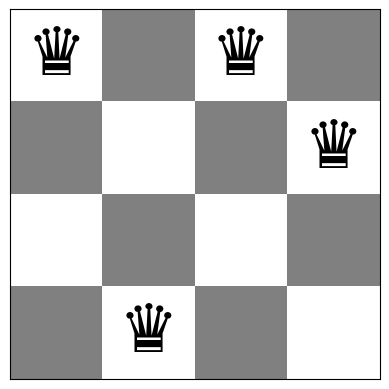

Bước 1: quân hậu ở cột 3 di chuyển từ hàng 1 → hàng 2 | xung đột: 3 → 1


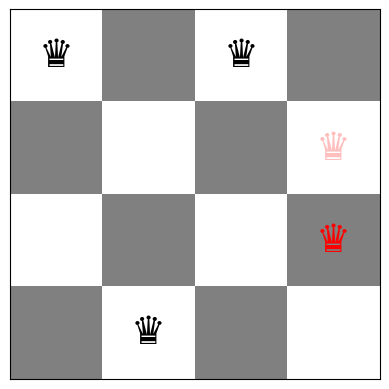

Bước 2: quân hậu ở cột 0 di chuyển từ hàng 0 → hàng 1 | xung đột: 1 → 0


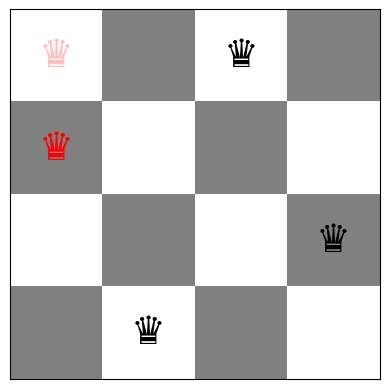


Kết quả: [1 3 0 2] với 0 xung đột → Lời giải tối ưu


In [182]:
n = 4
start = [0, 3, 0, 1]
print("Bàn cờ ban đầu:")
show_board(start)

final, c, history, path = hill_climb(start)

for step in range(1, len(path)):
    prev, cur = path[step - 1], path[step]
    col = np.flatnonzero(prev != cur)[0]
    print(f"Bước {step}: quân hậu ở cột {col} di chuyển từ hàng {prev[col]} "
          f"→ hàng {cur[col]} | xung đột: {history[step-1]} → {history[step]}")
    show_move(prev, cur, step)

print(f"\nKết quả: {final} với {c} xung đột "
      + ("→ Lời giải tối ưu" if c == 0 else "→ Mắc kẹt ở cực tiểu cục bộ"))

Bàn cờ ban đầu:
Board with 6 conflicts.


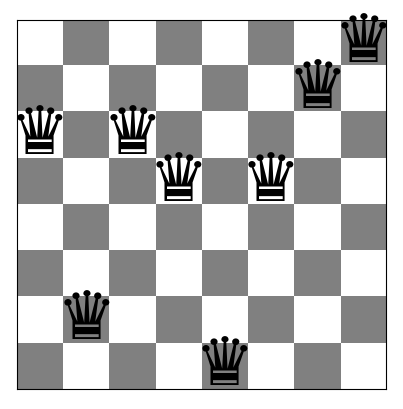

Bước 1: quân hậu ở cột 1 di chuyển từ hàng 6 → hàng 0 | xung đột: 6 → 5


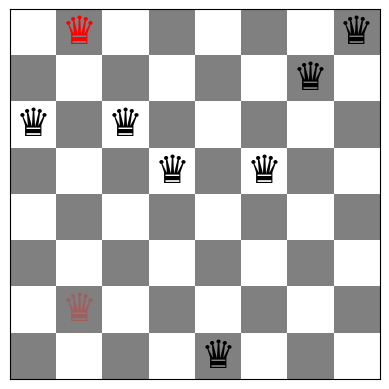

Bước 2: quân hậu ở cột 0 di chuyển từ hàng 2 → hàng 5 | xung đột: 5 → 4


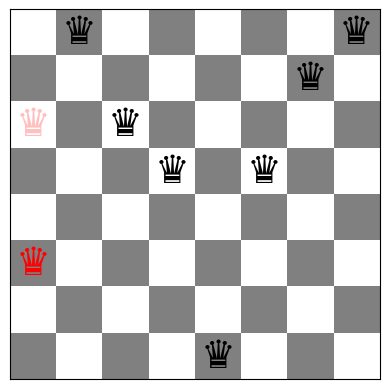

Bước 3: quân hậu ở cột 3 di chuyển từ hàng 3 → hàng 6 | xung đột: 4 → 3


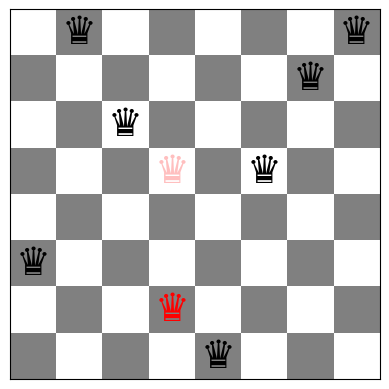

Bước 4: quân hậu ở cột 7 di chuyển từ hàng 0 → hàng 3 | xung đột: 3 → 2


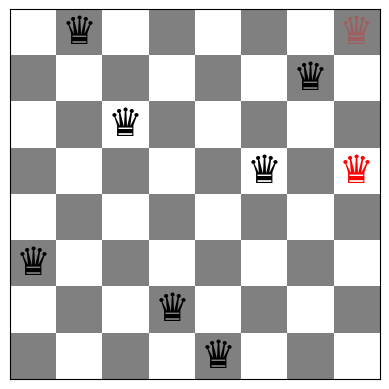


Kết quả: [5 0 2 6 7 3 1 3] với 2 xung đột → Mắc kẹt ở cực tiểu cục bộ


In [183]:
n = 8
start = [2, 6, 2, 3, 7, 3, 1, 0]
print("Bàn cờ ban đầu:")
show_board(start)

final, c, history, path = hill_climb(start)

for step in range(1, len(path)):
    prev, cur = path[step - 1], path[step]
    col = np.flatnonzero(prev != cur)[0]
    print(f"Bước {step}: quân hậu ở cột {col} di chuyển từ hàng {prev[col]} "
          f"→ hàng {cur[col]} | xung đột: {history[step-1]} → {history[step]}")
    show_move(prev, cur, step)

print(f"\nKết quả: {final} với {c} xung đột "
      + ("→ Lời giải tối ưu" if c == 0 else "→ Mắc kẹt ở cực tiểu cục bộ"))

## Task 2: Inefficient Stochastic Hill Climbing [10 Points] (Thuật toán leo đồi ngẫu nhiên kém hiệu quả)

Modify the algorithm for steepest-ascend hill climbing by choosing randomly from among all uphill moves till you have reached a local optimum.
- (Hãy sửa đổi thuật toán leo đồi theo hướng dốc nhất (steepest-ascent hill climbing) bằng cách chọn ngẫu nhiên một bước đi trong số tất cả các bước đi hướng lên, cho đến khi đạt tới một cực trị địa phương (local optimum).)

- Ở task 1, chúng ta chọn láng giềng tốt nhất. Còn ở task 2, chúng ta sẽ chọn ngẫu nhiên 1 trong những láng giềng tốt hơn ở trạng thái hiện tại.

In [184]:
def stochastic_hill_climb(board, max_steps=1000):
    """
    Inefficient Stochastic Hill Climbing cho bài toán n-Queens.
    Mỗi bước: tính xung đột của TẤT CẢ láng giềng, rồi chọn ngẫu nhiên
    một láng giềng trong số các láng giềng tốt hơn trạng thái hiện tại.
    Trả về: (bàn cờ cuối, số xung đột cuối, lịch sử số xung đột, danh sách bàn cờ qua từng bước)
    """
    current_state = np.array(board)
    current_c = conflicts(current_state)
    history = [current_c]
    path = [current_state.copy()]

    for step in range(max_steps):
        # Gom tất cả các bước đi lên dốc (láng giềng có ít xung đột hơn)
        uphill = []
        for nb in neighbors(current_state):
            c = conflicts(nb)
            if c < current_c:
                uphill.append((nb, c))

        # Không còn bước đi lên dốc → cực tiểu cục bộ (hoặc đã đạt 0) → dừng
        if len(uphill) == 0:
            break

        # Chọn ngẫu nhiên một bước đi lên dốc
        idx = np.random.randint(len(uphill))
        current_state, current_c = uphill[idx]
        history.append(current_c)
        path.append(current_state.copy())

    return current_state, current_c, history, path

Bàn cờ ban đầu:
Board with 3 conflicts.


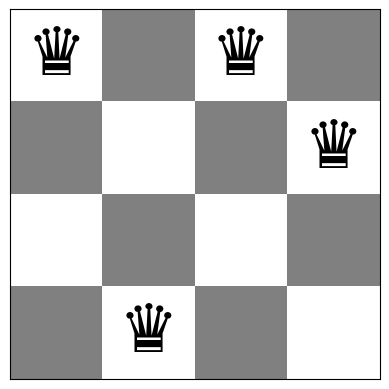

Bước 1: quân hậu ở cột 1 di chuyển từ hàng 3 -> hàng 2 | xung đột: 3 -> 2


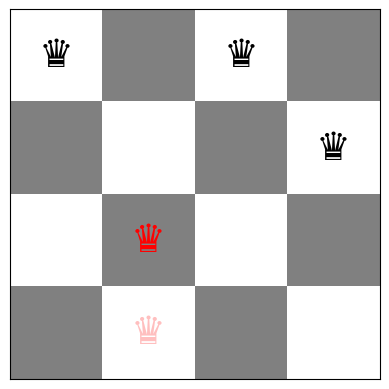

Bước 2: quân hậu ở cột 2 di chuyển từ hàng 0 -> hàng 3 | xung đột: 2 -> 1


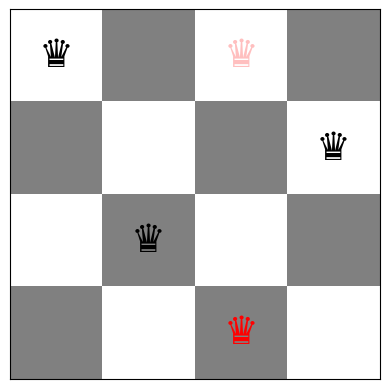


Kết quả: [0 2 3 1] với 1 xung đột -> Mắc kẹt ở cực tiểu cục bộ


In [185]:
n = 4
start = [0, 3, 0, 1]
print("Bàn cờ ban đầu:")
show_board(start)

final, c, history, path = stochastic_hill_climb(start)

for step in range(1, len(path)):
    prev, cur = path[step - 1], path[step]
    col = np.flatnonzero(prev != cur)[0]
    print(f"Bước {step}: quân hậu ở cột {col} di chuyển từ hàng {prev[col]} "
          f"-> hàng {cur[col]} | xung đột: {history[step-1]} -> {history[step]}")
    show_move(prev, cur, step)

print(f"\nKết quả: {final} với {c} xung đột "
      + ("-> Lời giải tối ưu" if c == 0 else "-> Mắc kẹt ở cực tiểu cục bộ"))

Bàn cờ ban đầu:
Board with 6 conflicts.


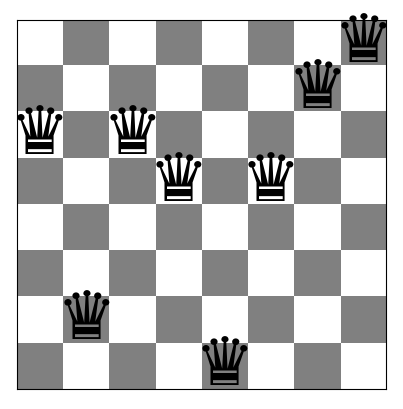

Bước 1: quân hậu ở cột 7 di chuyển từ hàng 0 -> hàng 5 | xung đột: 6 -> 5


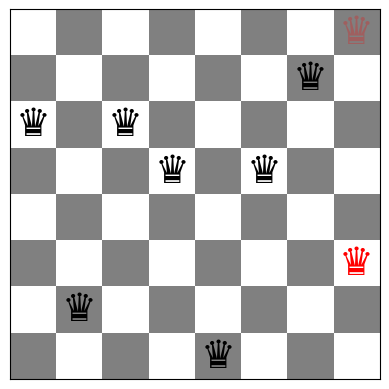

Bước 2: quân hậu ở cột 5 di chuyển từ hàng 3 -> hàng 0 | xung đột: 5 -> 4


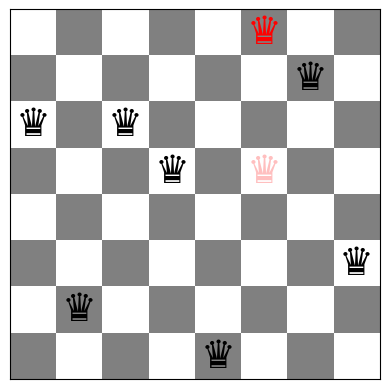

Bước 3: quân hậu ở cột 6 di chuyển từ hàng 1 -> hàng 7 | xung đột: 4 -> 3


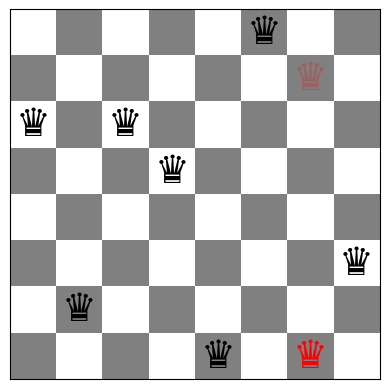

Bước 4: quân hậu ở cột 2 di chuyển từ hàng 2 -> hàng 1 | xung đột: 3 -> 1


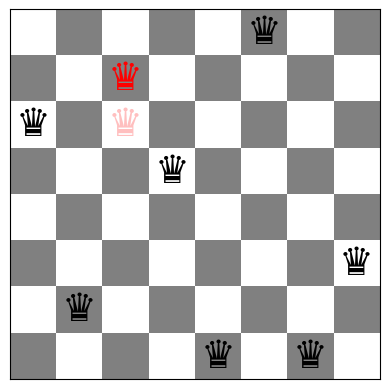


Kết quả: [2 6 1 3 7 0 7 5] với 1 xung đột -> Mắc kẹt ở cực tiểu cục bộ


In [186]:
n = 8
start = [2, 6, 2, 3, 7, 3, 1, 0]
print("Bàn cờ ban đầu:")
show_board(start)

final, c, history, path = stochastic_hill_climb(start)

for step in range(1, len(path)):
    prev, cur = path[step - 1], path[step]
    col = np.flatnonzero(prev != cur)[0]
    print(f"Bước {step}: quân hậu ở cột {col} di chuyển từ hàng {prev[col]} "
          f"-> hàng {cur[col]} | xung đột: {history[step-1]} -> {history[step]}")
    show_move(prev, cur, step)

print(f"\nKết quả: {final} với {c} xung đột "
      + ("-> Lời giải tối ưu" if c == 0 else "-> Mắc kẹt ở cực tiểu cục bộ"))

__Important note:__ This is a very expensive algorithm since it has to calculate the objective function (number of conflicts) for all possible moves. The next algorithm produces the same result, but with much less computational cost.
* (__Lưu ý quan trọng__: Đây là thuật toán rất tốn kém, vì phải tính hàm mục tiêu (số xung đột) cho tất cả các bước di chuyển có thể. Thuật toán tiếp theo cho ra cùng kết quả, nhưng với chi phí tính toán thấp hơn nhiều.)

#### So sánh giữa task 1 và task 2: `steepest-ascent hill climbing` vs `stochastic hill climbing`
- Với task 1, chúng ta chọn láng giềng tốt nhất -> kết quả sẽ cho ra 1 hướng duy nhất. Nhưng ở task 2 lại khác, việc chọn ngẫu nhiên này, sẽ giúp cho bài toán có nhiều hướng đi và mỗi lần chạy sẽ cho ra kết quả khác nhau. Quan sát bàn cờ 4-Queens với nhiều lần chạy có cho ra kết quả khác với kết quả đã chạy ở Task 2 không?

In [187]:
start = [0, 3, 0, 1]
_, c1, _, _ = hill_climb(start)
results = [stochastic_hill_climb(start)[1] for _ in range(10)]
print(f"Steepest (tất định): {c1} xung đột")
print(f"Stochastic, 10 lần chạy: {results}")
print(f"-> số lần đạt 0 xung đột: {results.count(0)}/10")

Steepest (tất định): 0 xung đột
Stochastic, 10 lần chạy: [0, 0, 0, 0, 1, 1, 0, 1, 0, 1]
-> số lần đạt 0 xung đột: 6/10


In [188]:
#Và chúng ta sẽ xét thêm với bàn cờ 8 quân hậu:
start = [2, 6, 2, 3, 7, 3, 1, 0]
_, c1, _, _ = hill_climb(start)
results = [stochastic_hill_climb(start)[1] for _ in range(10)]
print(f"Steepest (tất định): {c1} xung đột")
print(f"Stochastic, 10 lần chạy: {results}")
print(f"-> số lần đạt 0 xung đột: {results.count(0)}/10")

Steepest (tất định): 2 xung đột
Stochastic, 10 lần chạy: [1, 1, 1, 1, 2, 1, 1, 1, 1, 1]
-> số lần đạt 0 xung đột: 0/10


### Nhận xét: so sánh Task 1 và Task 2 (cùng bàn cờ xuất phát)

| | Steepest-ascent HC | Inefficient Stochastic HC (10 lần chạy) |
|---|---|---|
| n = 4, `[0,3,0,1]` (3 xung đột) | luôn đạt **0** (3 → 1 → 0) | đạt 0 trong **6/10** lần, còn lại kẹt ở 1 |
| n = 8, `[2,6,2,3,7,3,1,0]` (6 xung đột) | luôn kẹt ở **2** | kẹt ở **1** trong 9/10 lần, 1 lần kẹt ở 2; không lần nào đạt 0 |

- **Steepest-ascent là tất định:** cùng bàn cờ xuất phát luôn đi đúng một đường và cho cùng kết quả. Nếu đường đó dẫn vào cực tiểu cục bộ thì lần nào cũng kẹt ở đó.
- **Stochastic HC có tính ngẫu nhiên:** mỗi lần chạy có thể đi đường khác và cho kết quả khác. Với n = 4, nó có thể kẹt (4/10 lần) trong khi Steepest luôn tìm được lời giải. Với n = 8, trên bàn cờ này nó thường kết thúc tốt hơn Steepest (1 so với 2 xung đột).
- **Kết luận:** chọn bước tốt nhất ở mỗi bước (tham lam) không đảm bảo kết quả cuối tốt nhất. Ngược lại, chọn ngẫu nhiên cũng không đảm bảo tốt hơn. Kết quả phụ thuộc vào bàn cờ xuất phát và vào may mắn. Hai thử nghiệm trên chỉ dùng một bàn cờ cho mỗi kích thước, nên chưa đủ để kết luận chung. Phần so sánh trên 100 bàn cờ ngẫu nhiên ở Task 6.
- Cả hai thuật toán đều có thể mắc kẹt ở cực tiểu cục bộ, nhất là khi n = 8. Đây là lý do cần Random Restarts (Task 4) và Simulated Annealing (Task 5).

## Task 3: Efficient Stochastic Hill Climbing [20 Points] (Thuật toán leo đồi ngẫu nhiên hiệu quả)

Stochastic hill climbing is in practice always implemented in the following way: 
(Trong thực tế, thuật toán leo đồi ngẫu nhiên (stochastic hill climbing) luôn được triển khai theo cách sau:)

1. Generate only a single random local neighbor at a time.
- (Chỉ tạo ra một trạng thái lân cận ngẫu nhiên tại mỗi thời điểm.)

2. Accept the move if it has a better objective function value than the current state. 
- (Chấp nhận bước di chuyển nếu trạng thái mới có giá trị hàm mục tiêu tốt hơn trạng thái hiện tại.)

3. Repeat till a stopping criterion is met.
- (Lặp lại cho đến khi đạt đến tiêu chí dừng.)

This is very efficient if each state has many possible successor states. This method is called "First-choice hill climbing" in the textbook and in practice this is just called "Stochastic Hill Climbing."
- (Phương pháp này đặc biệt hiệu quả nếu mỗi trạng thái có rất nhiều trạng thái kế tiếp khả dĩ. Trong giáo trình, phương pháp này được gọi là "leo đồi chọn lựa đầu tiên" (first-choice hill climbing), còn trong thực tế, nó thường được gọi đơn giản là "leo đồi ngẫu nhiên".)

__Notes:__ 

* Detecting local optima is tricky since you never calculate the objective function for all local moves! A popular option is to stop if you were not able to improve the objective function during the last $x$ tries. You will need to argue what the right number for $x$ is. It will depend on the size of the board. Hint: You are sampling random local moves from the set of all possible moves with replacement and you want to make sure that you trie almost all before you stop.
- (Việc phát hiện các cực trị địa phương (local optima) khá phức tạp vì bạn không tính toán giá trị hàm mục tiêu cho tất cả các bước di chuyển khả dĩ! Một cách tiếp cận phổ biến là dừng thuật toán nếu bạn không thể cải thiện giá trị hàm mục tiêu sau $x$ lần thử liên tiếp. Bạn cần lập luận để xác định giá trị $x$ phù hợp; giá trị này sẽ phụ thuộc vào kích thước của bàn cờ. Gợi ý: Bạn đang lấy mẫu ngẫu nhiên các bước di chuyển từ tập hợp tất cả các bước khả dĩ (có hoàn lại), và bạn cần đảm bảo rằng mình đã thử gần như tất cả các khả năng trước khi quyết định dừng lại.)

### Mô tả thuật toán
1. Mỗi lần chỉ sinh **một** láng giềng ngẫu nhiên: chọn ngẫu nhiên một cột, rồi chọn ngẫu nhiên một hàng **khác** hàng hiện tại. Kỹ thuật dùng là bốc trong $n-1$ giá trị, nếu giá trị bốc được ≥ hàng hiện tại thì cộng thêm 1.
2. Nếu láng giềng đó có ít xung đột hơn thì nhận ngay và đặt lại bộ đếm thất bại về 0. Nếu không thì tăng bộ đếm.
3. Dừng khi đạt 0 xung đột, hoặc khi thất bại liên tiếp $x$ lần. Ngoài ra có `max_iters` để chắc chắn thuật toán không lặp vô hạn.

### Chọn giá trị x
Mỗi trạng thái có $N = n(n-1)$ láng giềng, được bốc ngẫu nhiên **có hoàn lại**. Theo bài toán sưu tập phiếu (coupon collector), số lần bốc kỳ vọng để gặp đủ $N$ láng giềng khác nhau xấp xỉ $N \ln N$. Vì vậy chọn $x = \lceil N \ln N \rceil$:
- $n = 4$: $N = 12$, $x = 30$
- $n = 8$: $N = 56$, $x = 226$

$x$ tăng theo kích thước bàn cờ, đúng như gợi ý của đề.

In [189]:
import math

def first_choice_hill_climb(board, max_tries=None, max_iters=100000):
    """
    Efficient Stochastic (First-choice) Hill Climbing cho bài toán n-Queens.
    Mỗi lần chỉ sinh MỘT láng giềng ngẫu nhiên; nhận nếu tốt hơn trạng thái hiện tại.
    Dừng khi đạt 0 xung đột hoặc thất bại liên tiếp max_tries lần.
    Trả về: (bàn cờ cuối, số xung đột cuối, lịch sử số xung đột, số lần gọi conflicts)
    """
    current_state = np.array(board)
    n = len(current_state)
    current_c = conflicts(current_state)
    history = [current_c]
    evals = 1                                   # đếm số lần gọi conflicts()

    if max_tries is None:                       # x = N ln N, với N = n(n-1) láng giềng
        N = n * (n - 1)
        max_tries = math.ceil(N * math.log(N))

    fails = 0
    for _ in range(max_iters):
        if current_c == 0 or fails >= max_tries:
            break

        # Sinh 1 láng giềng ngẫu nhiên: chọn cột, chọn hàng KHÁC hàng hiện tại
        col = np.random.randint(n)
        row = np.random.randint(n - 1)
        if row >= current_state[col]:
            row += 1
        nb = current_state.copy()
        nb[col] = row

        c = conflicts(nb)
        evals += 1
        if c < current_c:                       # tốt hơn → nhận, reset bộ đếm thất bại
            current_state, current_c = nb, c
            history.append(current_c)
            fails = 0
        else:
            fails += 1

    return current_state, current_c, history, evals

In [190]:
for start in [[0, 3, 0, 1], [2, 6, 2, 3, 7, 3, 1, 0]]:
    final, c, history, evals = first_choice_hill_climb(start)
    print(f"n = {len(start)} | xung đột: {history} | {len(history)-1} bước, "
          f"{evals} lần gọi conflicts() → {final}")

n = 4 | xung đột: [3, 2, 1] | 2 bước, 36 lần gọi conflicts() → [0 2 3 1]
n = 8 | xung đột: [6, 5, 4, 3, 2, 1] | 5 bước, 302 lần gọi conflicts() → [2 0 6 3 7 4 1 5]


#### - Phần đo lường:

In [191]:
import time

def measure(algo, n, runs=100, seed=0):
    np.random.seed(seed)                        # cùng seed → cả 3 thuật toán chạy trên cùng 100 bàn cờ
    boards = [random_board(n) for _ in range(runs)]
    steps, evals, finals, times = [], [], [], []
    for b in boards:
        t0 = time.perf_counter()
        out = algo(b)
        times.append(time.perf_counter() - t0)
        history = out[2]
        steps.append(len(history) - 1)
        finals.append(out[1])
        if algo is first_choice_hill_climb:
            evals.append(out[3])
        else:
            evals.append(1 + len(history) * n * (n - 1))
    return (np.mean(steps), np.mean(evals), np.mean(finals),
            100 * np.mean(np.array(finals) == 0), 1000 * np.mean(times))

algos = [("Steepest-ascent HC", hill_climb),
         ("Ineff. Stochastic HC", stochastic_hill_climb),
         ("Efficient Stochastic HC", first_choice_hill_climb)]

print(f"{'Thuật toán':<25}{'n':>3}{'Số bước':>10}{'Lần gọi f':>12}{'f cuối':>9}{'% tối ưu':>10}{'Thời gian (ms)':>16}")
for n in [4, 8]:
    for name, algo in algos:
        s, e, f, p, t = measure(algo, n)
        print(f"{name:<25}{n:>3}{s:>10.2f}{e:>12.1f}{f:>9.2f}{p:>9.0f}%{t:>16.3f}")

Thuật toán                 n   Số bước   Lần gọi f   f cuối  % tối ưu  Thời gian (ms)
Steepest-ascent HC         4      1.68        33.2     0.51       55%           0.308
Ineff. Stochastic HC       4      1.86        35.3     0.71       38%           0.288
Efficient Stochastic HC    4      1.82        32.7     0.87       27%           0.463
Steepest-ascent HC         8      3.17       234.5     1.30       12%           2.643
Ineff. Stochastic HC       8      4.91       332.0     1.24       20%           4.104
Efficient Stochastic HC    8      5.14       257.7     1.21       17%           4.718


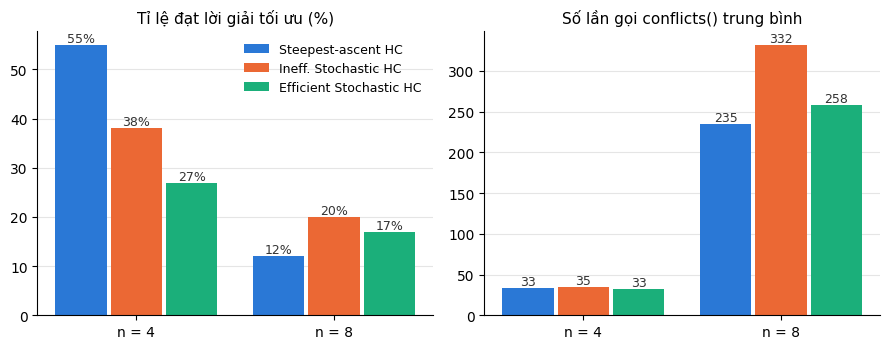

In [ ]:

bar_data = {}                                   # {(tên thuật toán, n): (lần gọi f, % tối ưu)}
for n in [4, 8]:
    for name, algo in algos:
        s, e, f, p, t = measure(algo, n)
        bar_data[(name, n)] = (e, p)

names  = [name for name, _ in algos]
colors = ["#2a78d6", "#eb6834", "#1baf7a"]
sizes  = [4, 8]
x = np.arange(len(sizes))                       # vị trí nhóm cột: n = 4, n = 8
w = 0.26                                        # độ rộng mỗi cột

fig, axs = plt.subplots(1, 2, figsize=(9, 3.6))
panels = [(axs[0], 1, "Tỉ lệ đạt lời giải tối ưu (%)",     "{:.0f}%"),   # vị trí 1: % tối ưu
          (axs[1], 0, "Số lần gọi conflicts() trung bình", "{:.0f}")]    # vị trí 0: số lần gọi f
for ax, idx, title, fmt in panels:
    for k, name in enumerate(names):
        vals = [bar_data[(name, n)][idx] for n in sizes]
        bars = ax.bar(x + (k - 1) * (w + 0.02), vals, w, color=colors[k], label=name)
        for b, v in zip(bars, vals):            # ghi số trên đầu mỗi cột
            ax.text(b.get_x() + b.get_width() / 2, v, fmt.format(v),
                    ha="center", va="bottom", fontsize=9, color="#333")
    ax.set_xticks(x)
    ax.set_xticklabels([f"n = {s}" for s in sizes])
    ax.set_title(title, fontsize=11)
    ax.grid(axis="y", color="#e5e5e5", linewidth=0.8)
    ax.set_axisbelow(True)                      # lưới nằm dưới cột
    ax.spines["top"].set_visible(False)         # bỏ khung trên và bên phải
    ax.spines["right"].set_visible(False)
axs[0].legend(frameon=False, fontsize=9, loc="upper right")
plt.tight_layout()
plt.show()

### Nhận xét: đánh đổi giữa chất lượng và chi phí

- **Chất lượng:**
  - Với n = 4, Steepest-ascent tốt nhất (55% tối ưu, f cuối 0.51).
  - Với n = 8, ba thuật toán gần ngang nhau (f cuối 1.21–1.30). Hai thuật toán ngẫu nhiên nhỉnh hơn một chút (17–20% so với 12%).
  - Cả ba đều thường mắc kẹt ở cực tiểu cục bộ khi n = 8.
- **Số lần gọi f:**
  - Steepest và Ineff. Stochastic đều đánh giá toàn bộ $n(n-1)$ láng giềng ở mỗi bước.
  - Ineff. Stochastic cần nhiều bước hơn nên tốn nhiều nhất (332 lần với n = 8).
  - Efficient Stochastic tốn 257.7 lần, gần bằng Steepest. Lý do là phần lớn số lần gọi f nằm ở cuối, khi phải thất bại liên tiếp $x = 226$ lần mới dừng.
- **Thời gian:**
  - Với n = 4, chênh lệch không đáng kể (0.29–0.46 ms).
  - Với n = 8, Steepest nhanh nhất (2.64 ms), Efficient Stochastic chậm nhất (4.72 ms). Nguyên nhân là mỗi vòng lặp còn tốn thêm chi phí sinh số ngẫu nhiên và sao chép mảng. Lợi thế của Efficient Stochastic chỉ thể hiện khi n lớn.
- **Đánh đổi:**
  - Đánh giá toàn bộ láng giềng (Steepest, Ineff. Stochastic) giúp biết chắc đã đến cực tiểu cục bộ, nhưng mỗi bước tốn kém.
  - Efficient Stochastic rẻ ở mỗi bước, nhưng phải chấp nhận tiêu chí dừng gần đúng: $x$ lớn thì tốn hơn, $x$ nhỏ thì dễ dừng sớm. Điều này có thể giải thích tỉ lệ tối ưu thấp hơn ở n = 4 (27%).
- **Kết luận:** với n nhỏ, Steepest-ascent đơn giản và nhanh nhất. Cả ba thuật toán đều dễ kẹt ở cực tiểu cục bộ, nên cần Random Restarts (Task 4) hoặc Simulated Annealing (Task 5).a

## Task 4: Hill Climbing Search with Random Restarts [10 Points]

Hill climbing will often end up in local optima. Restart the each of the three hill climbing algorithm up to 100 times with a random board to find a better (hopefully optimal) solution. Note that restart just means to run the algorithm several times starting with a new random board.

In [ ]:
import time
import numpy as np
import pandas as pd

HC_ALGORITHMS = {
    "Steepest-ascent": hill_climb,
    "Inefficient Stochastic": stochastic_hill_climb,
    "Efficient Stochastic": first_choice_hill_climb,
}

def random_restart_hill_climb(n, algorithm, max_restarts=100):
    """Thử tối đa max_restarts bàn cờ ngẫu nhiên (tính cả lần đầu).
    Trả về nghiệm tốt nhất, f tốt nhất, số lần đã thử và history của lần tốt nhất.
    """
    if n < 4 or max_restarts < 1:
        raise ValueError("Yêu cầu n >= 4 và max_restarts >= 1")

    best_board, best_f, best_history = None, float("inf"), None
    attempts = 0
    for _ in range(max_restarts):
        attempts += 1
        initial = random_board(n)
        final_board, final_f, history, _ = algorithm(initial)
        if final_f < best_f:
            best_board = np.array(final_board).copy()
            best_f = int(final_f)
            best_history = list(history)
        if best_f == 0:  
            break

    return best_board, best_f, attempts, best_history

np.random.seed(2026)
for n in [4, 8]:
    print(f"\n===== Random Restart: n={n} =====")
    for name, algorithm in HC_ALGORITHMS.items():
        t0 = time.perf_counter()
        board_best, f_best, attempts, _ = random_restart_hill_climb(n, algorithm)
        elapsed_ms = (time.perf_counter()-t0)*1000
        print(f"{name:24s} | f tốt nhất={f_best} | lần khởi động={attempts:3d}/100 | {elapsed_ms:.2f} ms")
        print("  Nghiệm tốt nhất:", board_best.tolist())



===== Random Restart: n=4 =====
Steepest-ascent          | f tốt nhất=0 | lần khởi động=  2/100 | 0.56 ms
  Nghiệm tốt nhất: [1, 3, 0, 2]
Inefficient Stochastic   | f tốt nhất=0 | lần khởi động=  1/100 | 0.44 ms
  Nghiệm tốt nhất: [2, 0, 3, 1]
Efficient Stochastic     | f tốt nhất=0 | lần khởi động=  6/100 | 3.48 ms
  Nghiệm tốt nhất: [2, 0, 3, 1]

===== Random Restart: n=8 =====
Steepest-ascent          | f tốt nhất=0 | lần khởi động=  6/100 | 11.11 ms
  Nghiệm tốt nhất: [2, 6, 1, 7, 5, 3, 0, 4]
Inefficient Stochastic   | f tốt nhất=0 | lần khởi động= 15/100 | 57.35 ms
  Nghiệm tốt nhất: [4, 1, 3, 5, 7, 2, 0, 6]
Efficient Stochastic     | f tốt nhất=0 | lần khởi động=  1/100 | 1.78 ms
  Nghiệm tốt nhất: [5, 3, 0, 4, 7, 1, 6, 2]


In [ ]:
def experiment_random_restart(ns=(4, 8), runs=100, max_restarts=100, seed=2026):
    rows = []
    for n in ns:
        for name, algo in HC_ALGORITHMS.items():
            fs, attempts_list, elapsed_list = [], [], []
            for k in range(runs):
                np.random.seed(seed + 1000*n + k)
                t0 = time.perf_counter()
                _, f_best, attempts, _ = random_restart_hill_climb(n, algo, max_restarts)
                elapsed_list.append((time.perf_counter()-t0)*1000)
                fs.append(f_best)
                attempts_list.append(attempts)
            rows.append({
                "n": n, "Thuật toán": name, "Lần chạy": runs,
                "f tốt nhất": min(fs), "f trung bình": np.mean(fs),
                "Tỉ lệ thành công (%)": 100*np.mean(np.array(fs)==0),
                "Số khởi động TB": np.mean(attempts_list),
                "Thời gian TB (ms)": np.mean(elapsed_list)
            })
    return pd.DataFrame(rows)

rr_results = experiment_random_restart(runs=100, max_restarts=100)
display(rr_results.round(3))


,n,Thuật toán,Lần chạy,f tốt nhất,f trung bình,Tỉ lệ thành công (%),Số khởi động TB,Thời gian TB (ms)
0,4,Steepest-ascent,100,0,0.0,100.0,2.47,0.520
1,4,Inefficient Stochastic,100,0,0.0,100.0,3.11,0.715
2,4,Efficient Stochastic,100,0,0.0,100.0,3.15,0.778
3,8,Steepest-ascent,100,0,0.0,100.0,6.87,13.215
4,8,Inefficient Stochastic,100,0,0.0,100.0,8.13,21.890
5,8,Efficient Stochastic,100,0,0.0,100.0,7.30,45.068


#### **Nhận xét:**

**Đối với n = 4:**

Cả ba thuật toán đều đạt tỉ lệ thành công 100% với số xung đột tốt nhất và trung bình bằng 0. Steepest-ascent có số lần khởi động trung bình thấp nhất và thời gian thực hiện nhanh nhất. Efficient Stochastic có thời gian lớn nhất, số lần khởi động trung bình cũng là lớn nhất.

**Đối với n = 8:**
Cả ba thuật toán tiếp tục đạt tỉ lệ thành công 100%, tuy nhiên số lần khởi động và thời gian thực hiện đều tăng so với n=4. Efficient Stochastic có số lần khởi động trung bình thấp hơn hơn Inefficient Stochastic, nhưng thời gian thực hiện lại lớn nhất. Trong khi đó, Steepest-ascent vẫn tiếp tục có số lần khởi động TB thấp nhất và thời gian thực hiện nhanh nhất.

Kết quả cho thấy Random Restart giúp cả ba thuật toán tìm được nghiệm không xung đột trong tất cả 100 lần thử ở cả hai kích thước bàn cờ. Khi n tăng từ 4 lên 8, chi phí tính toán tăng đáng kể. Đáng chú ý, thuật toán có số lần khởi động ít hơn chưa chắc có thời gian thực hiện nhanh hơn, vì thời gian còn phụ thuộc vào chi phí tìm kiếm trong mỗi lần khởi động. 

Trong thí nghiệm này, Steepest-ascent có hiệu quả tốt nhất về thời gian ở cả hai kích thước bàn cờ.

## Task 5: Simulated Annealing [10 Points]

Simulated annealing is a form of efficient stochastic hill climbing that avoid local optima by also allowing downhill moves with a probability proportional to a temperature. The temperature is decreased in every iteration following an annealing schedule. You have to experiment with the annealing schedule (Google to find guidance on this).


1. Implement simulated annealing for the n-Queens problem.
2. Create a visualization of the search process (a line chart of how the number if conflict changes as the algorithm progresses).
3. Use this visualization for experiments with different choices for the annealing schedule and discuss what you have learned.

n=4, board đầu=[1, 3, 0, 3], board tốt nhất=[1, 3, 0, 2], f=0, số vòng lặp=2, 0.13 ms
n=8, board đầu=[5, 5, 7, 5, 6, 3, 3, 5], board tốt nhất=[3, 1, 6, 4, 0, 7, 5, 2], f=0, số vòng lặp=1111, 15.92 ms


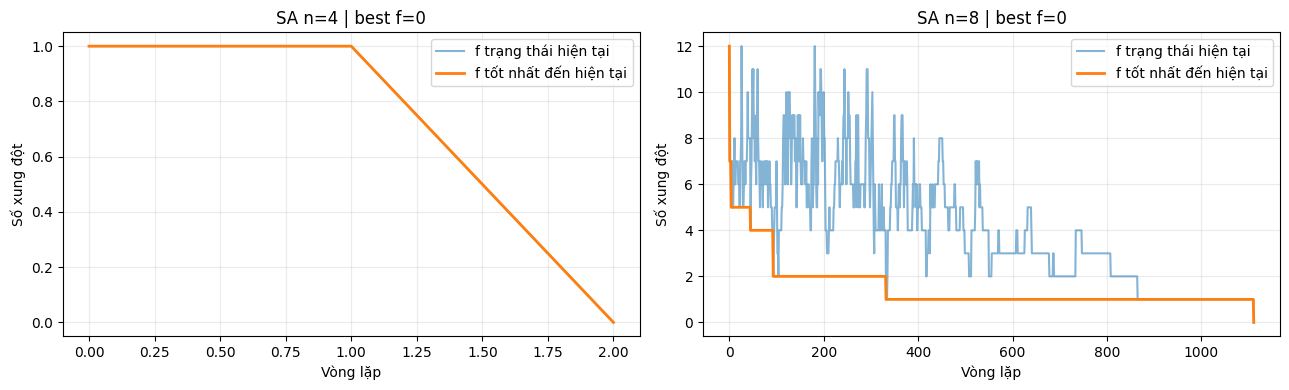

In [ ]:
import math

def simulated_annealing(board, T0=10.0, alpha=0.995, max_steps=10000,
                        schedule="exponential", min_temp=1e-6):
    """Trả về (best_board, best_conflicts, best_history, path).
    best_history[t]: giá trị f tốt nhất tìm được đến bước t.
    path: các trạng thái thực sự được chấp nhận (gồm trạng thái ban đầu).
    Ngoài ra, current_history ghi lại f của trạng thái hiện tại, có thể tăng/giảm.
    """
    if T0 <= 0 or max_steps < 1 or not (0 < alpha < 1):
        raise ValueError("Cần T0 > 0, max_steps >= 1, 0 < alpha < 1")
    if schedule not in ("exponential", "linear"):
        raise ValueError("schedule chỉ nhận 'exponential' hoặc 'linear'")
    current = np.array(board, dtype=int).copy()
    n = len(current)
    current_f = int(conflicts(current))
    best = current.copy()
    best_f = current_f
    best_history = [best_f]
    current_history = [current_f]
    path = [current.copy()]

    for t in range(max_steps):
        if best_f == 0:
            break
        T = T0 * (alpha ** t) if schedule == "exponential" else T0 * (1 - t/max_steps)
        if T <= min_temp:
            break

        
        col = np.random.randint(n)
        row = np.random.randint(n-1)
        if row >= current[col]:
            row += 1
        candidate = current.copy()
        candidate[col] = row
        new_f = int(conflicts(candidate))
        delta = new_f - current_f

        if delta <= 0 or np.random.random() < math.exp(-delta/T):
            current, current_f = candidate, new_f
            path.append(current.copy())
            if current_f < best_f:
                best, best_f = current.copy(), current_f

        current_history.append(current_f)
        best_history.append(best_f)

    return best, best_f, best_history, path, current_history

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for ax, n in zip(axes, [4, 8]):
    np.random.seed(2026+n)
    start = random_board(n)
    t0 = time.perf_counter()
    best, f_best, best_history, path, current_history = simulated_annealing(
        start, T0=10, alpha=0.995, max_steps=10000, schedule="exponential")
    ms = (time.perf_counter()-t0)*1000
    ax.plot(current_history, alpha=.55, label="f trạng thái hiện tại")
    ax.plot(best_history, linewidth=2, label="f tốt nhất đến hiện tại")
    ax.set(title=f"SA n={n} | best f={f_best}", xlabel="Vòng lặp", ylabel="Số xung đột")
    ax.legend()
    ax.grid(alpha=.25)
    print(f"n={n}, board đầu={start.tolist()}, board tốt nhất={best.tolist()}, "
          f"f={f_best}, số vòng lặp={len(current_history)-1}, {ms:.2f} ms")
plt.tight_layout()
plt.show()


#### **Nhận xét:**
**1. Khả năng tìm kiếm lời giải**

Thuật toán Simulated Annealing tìm được nghiệm tối ưu với số xung đột bằng 0 ở cả hai trường hợp n=4 và n=8. Với n=4, thuật toán hội tụ nhanh sau 2 vòng lặp, trong khi n=8 cần 1.111 vòng lặp. Điều này cho thấy bài toán có kích thước lớn hơn đòi hỏi nhiều bước tìm kiếm hơn trong hai lần chạy minh họa.

**2. Quá trình hội tụ**

Ở n=4, số xung đột giảm nhanh từ 1 xuống 0. Với n=8, số xung đột của trạng thái hiện tại dao động mạnh trong quá trình tìm kiếm, có thời điểm tăng lên 12. Tuy nhiên, số xung đột tốt nhất giảm dần và cuối cùng đạt 0. Điều này thể hiện khả năng chấp nhận trạng thái xấu hơn của Simulated Annealing để khám phá không gian tìm kiếm và tránh mắc kẹt tại cực tiểu cục bộ.

,n,Lịch nhiệt,T0,alpha,Số lần,f trung bình,Tỉ lệ thành công (%),Số vòng lặp TB,Thời gian TB (ms)
0,4,exponential,1.0,0.995,30,0.000,100.000,55.300,1.428
1,4,exponential,10.0,0.980,30,0.000,100.000,74.467,2.020
2,4,exponential,10.0,0.995,30,0.000,100.000,87.167,2.125
3,4,exponential,10.0,0.999,30,0.000,100.000,98.600,2.699
4,4,linear,10.0,NaN,30,0.000,100.000,100.500,2.595
5,8,exponential,1.0,0.995,30,0.067,93.333,753.033,9.823
6,8,exponential,10.0,0.980,30,0.333,66.667,515.600,6.576
7,8,exponential,10.0,0.995,30,0.033,96.667,1015.833,13.470
8,8,exponential,10.0,0.999,30,0.000,100.000,3564.967,46.870
9,8,linear,10.0,NaN,30,0.233,76.667,9332.167,267.185


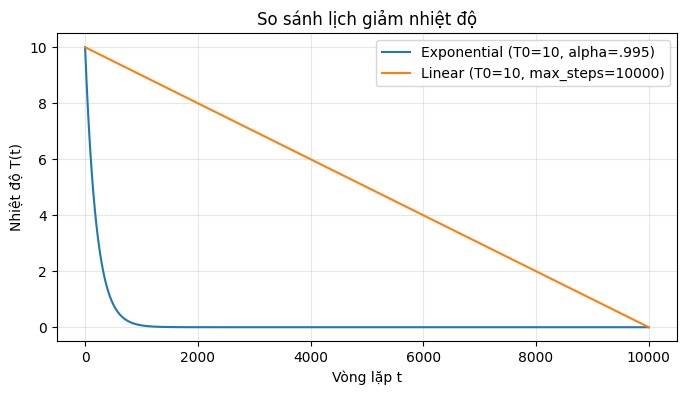

In [ ]:
def experiment_sa(n=8, runs=30, max_steps=10000, seed=2026):
    settings = [
        ("exponential", 1.0, 0.995),
        ("exponential", 10.0, 0.980),
        ("exponential", 10.0, 0.995),
        ("exponential", 10.0, 0.999),
        ("linear", 10.0, 0.995),
    ]
    rows = []
    for schedule, T0, alpha in settings:
        fs, steps, elapsed = [], [], []
        for k in range(runs):
            np.random.seed(seed + k)
            start = random_board(n)
            t0 = time.perf_counter()
            _, f_best, hist, _, _ = simulated_annealing(
                start, T0=T0, alpha=alpha, max_steps=max_steps, schedule=schedule)
            elapsed.append((time.perf_counter()-t0)*1000)
            fs.append(f_best)
            steps.append(len(hist)-1)
        rows.append({
            "Lịch nhiệt": schedule, "T0": T0,
            "alpha": alpha if schedule == "exponential" else np.nan,
            "Số lần": runs, "f trung bình": np.mean(fs),
            "Tỉ lệ thành công (%)": 100*np.mean(np.array(fs)==0),
            "Số vòng lặp TB": np.mean(steps),
            "Thời gian TB (ms)": np.mean(elapsed)
        })
    return pd.DataFrame(rows)

sa_results = experiment_sa(n=8, runs=30, max_steps=10000, seed=2026)
sa_two_sizes = pd.concat([
    experiment_sa(n=4, runs=30, max_steps=10000, seed=2026).assign(n=4),
    sa_results.assign(n=8)
], ignore_index=True)
display(sa_two_sizes[["n", "Lịch nhiệt", "T0", "alpha", "Số lần",
                      "f trung bình", "Tỉ lệ thành công (%)",
                      "Số vòng lặp TB", "Thời gian TB (ms)"]].round(3))

# Vẽ T(t) của hai lịch nhiệt trên cùng khoảng thời gian.
plot_max_steps = 10000
steps = np.arange(0, plot_max_steps + 1)
plt.figure(figsize=(8, 4))
plt.plot(steps, 10 * 0.995**steps, label="Exponential (T0=10, alpha=.995)")
plt.plot(steps, 10 * (1 - steps/plot_max_steps), label="Linear (T0=10, max_steps=10000)")
plt.xlabel("Vòng lặp t")
plt.ylabel("Nhiệt độ T(t)")
plt.title("So sánh lịch giảm nhiệt độ")
plt.grid(alpha=.3)
plt.legend()
plt.show()

**Ảnh hưởng của lịch giảm nhiệt độ:**

Kết quả được đánh giá dựa trên bốn tiêu chí: số xung đột trung bình, tỉ lệ thành công, số vòng lặp trung bình và thời gian thực hiện trung bình.

Qua 30 lần thử nghiệm cho mỗi cấu hình:

Đối với n = 4: Cả 5 cấu hình đều đạt tỉ lệ thành công 100% và số xung đột trung bình bằng 0, cho thấy chất lượng lời giải tương đương nhau. Tuy nhiên, xét về chi phí tính toán, Exponential (T0=1, α=0.995) hiệu quả nhất với số vòng lặp trung bình thấp nhất (55,300 vòng) và thời gian nhanh nhất (1,428 ms).

Đối với n = 8: Exponential (T0=10, α=0.999) có chất lượng lời giải tốt nhất với tỉ lệ thành công 100% và f trung bình bằng 0, nhưng cần 3.564,967 vòng lặp và 46,870 ms. Ngược lại, Exponential (T0=10, α=0.980) có chi phí tính toán thấp nhất với 515,600 vòng lặp và 6,576 ms, nhưng tỉ lệ thành công chỉ đạt 66,667% và f trung bình là 0,333. Đáng chú ý, Exponential (T0=10, α=0.995) đạt tỉ lệ thành công 96,667%, f trung bình 0,033 và thời gian 13,470 ms, thể hiện sự cân bằng tương đối tốt giữa chất lượng nghiệm và chi phí tính toán.

Kết luận: Khi tăng kích thước bàn cờ từ n=4 lên n=8, chi phí tính toán tăng và sự khác biệt giữa các cấu hình trở nên rõ rệt. Lịch giảm nhiệt chậm có thể cải thiện tỉ lệ thành công nhưng thường cần nhiều vòng lặp và thời gian hơn. Trong thí nghiệm này, nếu ưu tiên chất lượng nghiệm có thể chọn α=0.999; nếu ưu tiên cân bằng giữa chất lượng và thời gian, α=0.995 là lựa chọn phù hợp hơn.

## Task 6: Algorithm Behavior Analysis [20 Points]

### Comparison
Compare the algorithm using runtime and objective function values. Use boards of size 4 and 8 to explore how the different algorithms perform. Make sure that you run the algorithms for each board size several times (at least 100 times) with different starting boards and report averages.

Complete the following table

| Algorithm            | Board size | Avg. Run time | Avg. number of conflicts | % of runs ending in optimal solution  |
| -------------------- | ---------- | ------------- | --------------------------------- | - |
| Steepest asc. HC     |     4      |               |                                   |   |
| Ineff. Stochastic HC |     4      |               |                                   |   |
| Efficient Stochastic HC |     4      |               |                                   |   |
| Simulated Annealing  |     4      |               |                                   |   |
| Steepest asc. HC     |     8      |               |                                   |   |
| Ineff. Stochastic HC |     8      |               |                                   |   |
| Efficient Stochastic HC |     8      |               |                                   |   |
| Simulated Annealing  |     8      |               |                                   |   |

Hint: See [Profiling Python Code](../HOWTOs/profiling_code.ipynb) for help about how to measure runtime in Python.

Add the used code here:

In [ ]:
# Chạy cùng các bàn cờ đầu vào để việc so sánh công bằng; đo bằng perf_counter.
import time
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

COMPARE_ALGORITHMS = {
    "Steepest-ascent HC": hill_climb,
    "Inefficient Stochastic HC": stochastic_hill_climb,
    "Efficient Stochastic HC": first_choice_hill_climb,
    "Simulated Annealing": simulated_annealing,
}

def run_task6_algorithm(name, start):
    if name == "Simulated Annealing":
        out = simulated_annealing(start, T0=10.0, alpha=0.995,
                                  schedule="exponential", max_steps=10000)
    else:
        out = COMPARE_ALGORITHMS[name](start)
    return int(out[1]), list(out[2])

def task6_comparison(ns=(4, 8), runs=100, seed=2026):
    records = []
    for n in ns:
        rng = np.random.default_rng(seed + n)
        starts = [rng.integers(0, n, size=n) for _ in range(runs)]
        for algo_index, name in enumerate(COMPARE_ALGORITHMS):
            ending_fs, runtimes, step_counts = [], [], []
            for k, board in enumerate(starts):
                np.random.seed(seed + 100000*n + 1000*k + algo_index)
                t0 = time.perf_counter()
                f, hist = run_task6_algorithm(name, board.copy())
                runtimes.append((time.perf_counter() - t0)*1000)
                ending_fs.append(f)
                step_counts.append(len(hist)-1)
            records.append({
                "Thuật toán": name, "n": n, "Số lần chạy": runs,
                "Thời gian TB (ms)": np.mean(runtimes),
                "f trung bình": np.mean(ending_fs),
                "f tốt nhất": np.min(ending_fs),
                "Tỉ lệ tối ưu (%)": 100*np.mean(np.array(ending_fs)==0),
                "Số bước TB": np.mean(step_counts),
            })
    return pd.DataFrame(records)

comparison_task6 = task6_comparison(runs=100)
display(comparison_task6.round(3))

,Thuật toán,n,Số lần chạy,Thời gian TB (ms),f trung bình,f tốt nhất,Tỉ lệ tối ưu (%),Số bước TB
0,Steepest-ascent HC,4,100,0.171,0.66,0,41.0,1.68
1,Inefficient Stochastic HC,4,100,0.304,0.80,0,31.0,2.02
2,Efficient Stochastic HC,4,100,0.367,0.93,0,24.0,1.97
3,Simulated Annealing,4,100,1.050,0.00,0,100.0,113.83
4,Steepest-ascent HC,8,100,2.064,1.21,0,15.0,3.21
5,Inefficient Stochastic HC,8,100,2.795,1.30,0,15.0,4.80
6,Efficient Stochastic HC,8,100,3.207,1.42,0,9.0,4.79
7,Simulated Annealing,8,100,14.790,0.02,0,98.0,1126.08


### Nhận xét kết quả so sánh các thuật toán

Kết quả được đánh giá qua 100 lần chạy trên hai kích thước bàn cờ n=4 và n=8, dựa trên các tiêu chí: **thời gian trung bình, số xung đột trung bình, số xung đột tốt nhất, tỉ lệ tìm được nghiệm tối ưu và số bước trung bình**.

**Đối với n = 4:**

Simulated Annealing đạt chất lượng lời giải tốt nhất với tỉ lệ tối ưu 100% và số xung đột trung bình bằng 0, nhưng có thời gian thực hiện lớn nhất (1,050 ms) và số bước trung bình cao nhất (113,83 bước). Trong khi đó, Steepest-ascent HC có thời gian nhanh nhất (0,171 ms), nhưng tỉ lệ tìm được nghiệm tối ưu chỉ đạt 41%. Inefficient Stochastic HC và Efficient Stochastic HC có tỉ lệ tối ưu lần lượt là 31% và 24%.

**Đối với n = 8:**

Hiệu quả của ba thuật toán Hill Climbing giảm rõ rệt. Steepest-ascent HC và Inefficient Stochastic HC đều đạt tỉ lệ tối ưu 15%, trong khi Efficient Stochastic HC chỉ đạt 9%. Ngược lại, Simulated Annealing vẫn đạt tỉ lệ tối ưu cao nhất (98%) với số xung đột trung bình rất thấp (0,02), nhưng cần thời gian lớn nhất (14,790 ms) và trung bình 1.126,08 bước. Steepest-ascent HC tiếp tục có thời gian nhanh nhất (2,064 ms).

**Nhận xét chung:**

Khi kích thước bàn cờ tăng từ n=4 lên n=8, tỉ lệ tìm được nghiệm tối ưu của các thuật toán Hill Climbing giảm đáng kể, trong khi thời gian thực hiện tăng. Điều này cho thấy các thuật toán Hill Climbing dễ dừng tại cực tiểu cục bộ khi không còn trạng thái lân cận tốt hơn.

Simulated Annealing có khả năng tìm kiếm nghiệm tối ưu tốt hơn nhờ cơ chế chấp nhận những bước đi xấu hơn với xác suất phụ thuộc nhiệt độ, giúp tăng khả năng thoát khỏi cực tiểu cục bộ. Tuy nhiên, thuật toán phải đánh đổi bằng số bước và thời gian thực hiện lớn hơn.

**Kết luận:** Trong thí nghiệm này, Steepest-ascent HC phù hợp khi ưu tiên tốc độ thực hiện, còn Simulated Annealing hiệu quả hơn khi ưu tiên chất lượng lời giải và tỉ lệ tìm được nghiệm tối ưu.

### Algorithm Convergence

For each algorithm implemented, describe the typical convergence pattern (fast initial improvement vs. steady progress).
Include a plot showing the objective function value over iterations for one representative run of each algorithm on the 8-queens problem.
Explain which algorithms exhibit plateaus or getting stuck in local optima most frequently.

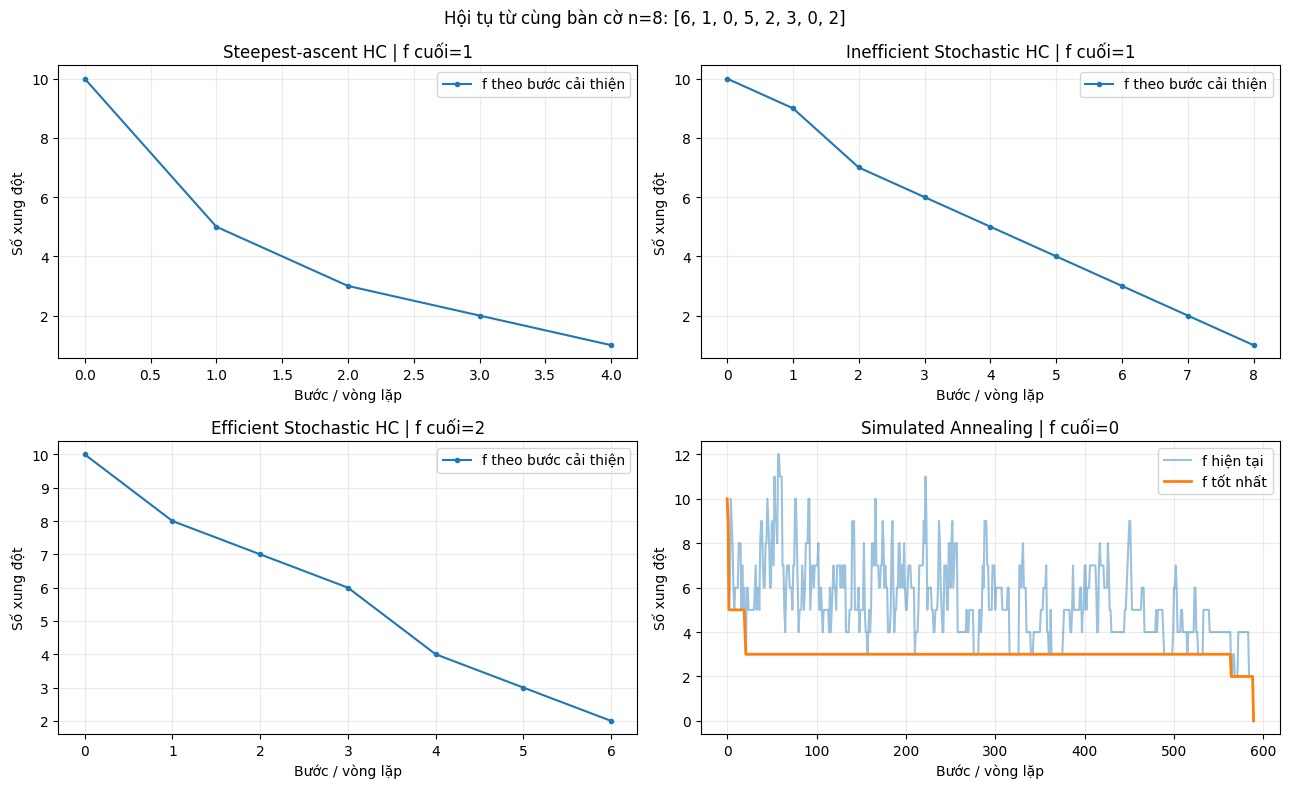

,f ban đầu,f cuối,Số bước hiển thị,Kẹt tại f>0
Steepest-ascent HC,10,1,4,True
Inefficient Stochastic HC,10,1,8,True
Efficient Stochastic HC,10,2,6,True
Simulated Annealing,10,0,589,False


Lưu ý: lịch sử HC chỉ gồm các bước cải thiện; SA ghi cả vòng lặp không cải thiện.


In [ ]:
# SA trình bày cả đường f hiện tại và f tốt nhất để thấy những bước chấp nhận nghiệm xấu.
seed_conv = 2026
initial_8 = np.random.default_rng(seed_conv).integers(0, 8, size=8)
fig, axes = plt.subplots(2, 2, figsize=(13, 8))
convergence_task6 = {}
for j, (name, algo) in enumerate(COMPARE_ALGORITHMS.items()):
    ax = axes.flat[j]
    np.random.seed(seed_conv + 100 + j)
    if name == "Simulated Annealing":
        best, f_end, best_hist, path, current_hist = simulated_annealing(
            initial_8.copy(), T0=10.0, alpha=0.995, max_steps=10000,
            schedule="exponential")
        ax.plot(current_hist, color="tab:blue", alpha=.45, label="f hiện tại")
        ax.plot(best_hist, color="tab:orange", lw=2, label="f tốt nhất")
        hist = best_hist
    else:
        end_board, f_end, hist, aux = algo(initial_8.copy())
        ax.plot(range(len(hist)), hist, marker="o", markersize=3, label="f theo bước cải thiện")
    convergence_task6[name] = {
        "f ban đầu": int(hist[0]), "f cuối": int(f_end),
        "Số bước hiển thị": len(hist)-1,
        "Kẹt tại f>0": bool(f_end > 0),
    }
    ax.set(title=f"{name} | f cuối={f_end}", xlabel="Bước / vòng lặp",
           ylabel="Số xung đột")
    ax.grid(alpha=.25)
    ax.legend()
fig.suptitle(f"Hội tụ từ cùng bàn cờ n=8: {initial_8.tolist()}")
plt.tight_layout()
plt.show()
display(pd.DataFrame.from_dict(convergence_task6, orient="index"))
print("Lưu ý: lịch sử HC chỉ gồm các bước cải thiện; SA ghi cả vòng lặp không cải thiện.")

### Nhận xét kết quả hội tụ của các thuật toán

Cả bốn thuật toán được thực hiện trên cùng bàn cờ ban đầu n=8, có cấu hình `[6, 1, 0, 5, 2, 3, 0, 2]` với số xung đột ban đầu là 10.

**1. Steepest-ascent Hill Climbing**

Số xung đột giảm nhanh từ 10 xuống 5 ngay bước đầu tiên và tiếp tục giảm xuống 1 sau 4 bước cải thiện. Tuy nhiên, thuật toán dừng lại tại f=1 mà chưa tìm được nghiệm tối ưu (f=0), cho thấy hiện tượng mắc kẹt tại cực tiểu cục bộ.

**2. Inefficient Stochastic Hill Climbing**

Số xung đột giảm đều từ 10 xuống 1 sau 8 bước cải thiện. So với Steepest-ascent, thuật toán cần nhiều bước hơn nhưng cũng dừng tại f=1, cho thấy việc lựa chọn ngẫu nhiên trong các bước cải thiện chưa đủ để thoát khỏi cực tiểu cục bộ.

**3. Efficient Stochastic Hill Climbing**

Số xung đột giảm từ 10 xuống 2 sau 6 bước cải thiện. Thuật toán dừng tại f=2, cao hơn hai thuật toán Hill Climbing còn lại. Điều này cho thấy việc thử ngẫu nhiên các trạng thái lân cận có thể dẫn đến dừng sớm khi không tìm được bước cải thiện trong giới hạn thử cho phép.

**4. Simulated Annealing**

Số xung đột của trạng thái hiện tại dao động mạnh trong quá trình tìm kiếm, có thời điểm tăng lên 12. Tuy nhiên, giá trị xung đột tốt nhất giảm dần từ 10 xuống 0 sau khoảng 590 vòng lặp. Nhờ khả năng chấp nhận trạng thái xấu hơn, Simulated Annealing đã tìm được nghiệm tối ưu, trong khi ba thuật toán Hill Climbing đều dừng ở trạng thái còn xung đột.

**Kết luận:**

Kết quả cho thấy các thuật toán Hill Climbing có khả năng giảm số xung đột nhanh trong những bước đầu nhưng dễ dừng sớm tại nghiệm chưa tối ưu. Ngược lại, Simulated Annealing cần nhiều vòng lặp hơn nhưng có khả năng khám phá không gian tìm kiếm tốt hơn, nhờ đó tìm được nghiệm không xung đột trong lần thử nghiệm này.

### Problem Size Scalability

Create a log-log plot showing how runtime scales with board size ($n=4, 8, 12, 16, 20$) for at least two algorithms.
Estimate the empirical time complexity (Big O) for each algorithm based on your results.
Identify which algorithm scales best for large problem sizes and explain why.

,n,Thuật toán,Thời gian TB (ms),f TB,Tỉ lệ tối ưu (%)
0,4,Steepest-ascent HC,0.210,0.80,35.0
1,4,Efficient Stochastic HC,0.262,0.80,35.0
2,8,Steepest-ascent HC,2.076,1.35,5.0
3,8,Efficient Stochastic HC,2.744,0.95,20.0
4,12,Steepest-ascent HC,10.159,1.70,10.0
5,12,Efficient Stochastic HC,11.441,1.60,5.0
6,16,Steepest-ascent HC,29.374,1.70,0.0
7,16,Efficient Stochastic HC,32.025,2.10,0.0
8,20,Steepest-ascent HC,87.019,2.65,0.0
9,20,Efficient Stochastic HC,121.278,2.45,5.0


Steepest-ascent HC: thời gian thực nghiệm xấp xỉ tăng theo n^3.71 trong phạm vi đo.
Efficient Stochastic HC: thời gian thực nghiệm xấp xỉ tăng theo n^3.70 trong phạm vi đo.


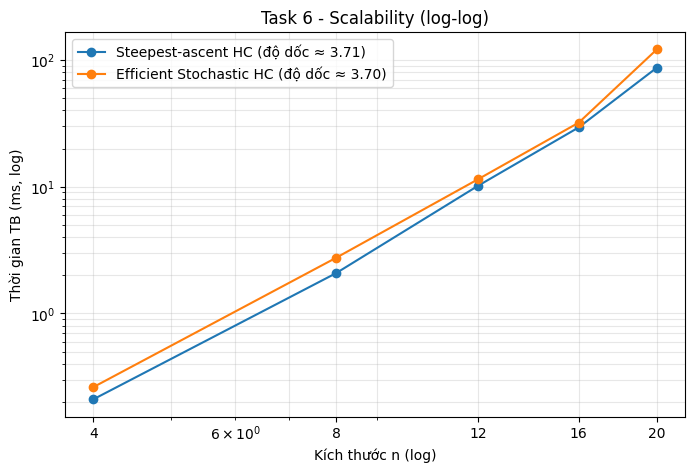

In [ ]:
# Dùng 2 thuật toán HC; giữ số phép thử mỗi n bằng nhau để so sánh.
# 20 lần / điểm dùng cho phép đo bổ sung; bảng so sánh chính phía trên vẫn là 100 lần.
SIZES_TASK6 = [4, 8, 12, 16, 20]
SCALE_RUNS = 20
SCALE_ALGOS = {
    "Steepest-ascent HC": hill_climb,
    "Efficient Stochastic HC": first_choice_hill_climb,
}
scaling_rows = []
for n in SIZES_TASK6:
    rng = np.random.default_rng(3000 + n)
    starts = [rng.integers(0, n, size=n) for _ in range(SCALE_RUNS)]
    for j, (name, algo) in enumerate(SCALE_ALGOS.items()):
        elapsed, fs = [], []
        for k, board in enumerate(starts):
            np.random.seed(9000 + n*100 + k*2 + j)
            t0 = time.perf_counter()
            out = algo(board.copy())
            elapsed.append((time.perf_counter()-t0)*1000)
            fs.append(int(out[1]))
        scaling_rows.append({"n": n, "Thuật toán": name,
                             "Thời gian TB (ms)": np.mean(elapsed),
                             "f TB": np.mean(fs), "Tỉ lệ tối ưu (%)": 100*np.mean(np.array(fs)==0)})
scaling_task6 = pd.DataFrame(scaling_rows)
display(scaling_task6.round(3))

plt.figure(figsize=(8, 5))
for name in SCALE_ALGOS:
    group = scaling_task6[scaling_task6["Thuật toán"] == name].sort_values("n")
    xs = group["n"].to_numpy(dtype=float)
    ys = group["Thời gian TB (ms)"].to_numpy(dtype=float)
    slope = np.polyfit(np.log(xs), np.log(np.maximum(ys, 1e-9)), 1)[0]
    plt.loglog(xs, ys, marker="o", label=f"{name} (độ dốc ≈ {slope:.2f})")
    print(f"{name}: thời gian thực nghiệm xấp xỉ tăng theo n^{slope:.2f} trong phạm vi đo.")
plt.xlabel("Kích thước n (log)")
plt.ylabel("Thời gian TB (ms, log)")
plt.title("Task 6 - Scalability (log-log)")
plt.xticks(SIZES_TASK6, [str(n) for n in SIZES_TASK6])
plt.grid(alpha=.3, which="both")
plt.legend()
plt.show()

### Nhận xét kết quả Problem Size Scalability

Kết quả được đánh giá trên các kích thước bàn cờ n = 4, 8, 12, 16, 20 với hai thuật toán Steepest-ascent Hill Climbing và Efficient Stochastic Hill Climbing, dựa trên ba tiêu chí: **thời gian thực hiện trung bình, số xung đột trung bình (f TB) và tỉ lệ tìm được nghiệm tối ưu**.

**1. Thời gian thực hiện**

Khi kích thước bàn cờ tăng từ n=4 lên n=20, thời gian thực hiện của cả hai thuật toán đều tăng đáng kể:

- Steepest-ascent tăng từ 0,210 ms lên 87,019 ms.
- Efficient Stochastic tăng từ 0,262 ms lên 121,278 ms.

Steepest-ascent có thời gian thực hiện thấp hơn Efficient Stochastic ở cả 5 kích thước bàn cờ.

**2. Chất lượng lời giải**

Khi n tăng, số xung đột trung bình nhìn chung tăng và tỉ lệ tìm được nghiệm tối ưu có xu hướng giảm.

Ở n=4, cả hai thuật toán đều đạt tỉ lệ tối ưu 35%. Tuy nhiên, đến n=16, cả hai đều không tìm được nghiệm tối ưu trong các lần thử. Tại n=20, Steepest-ascent có f trung bình 2,65 và tỉ lệ tối ưu 0%, trong khi Efficient Stochastic có f trung bình 2,45 và tỉ lệ tối ưu 5%.

Điều này cho thấy khi không gian tìm kiếm lớn hơn, các thuật toán Hill Climbing dễ dừng tại trạng thái còn xung đột.

**3. Phân tích biểu đồ log-log**

Biểu đồ log-log cho thấy thời gian thực hiện tăng nhanh theo kích thước bàn cờ. Độ dốc thực nghiệm của Steepest-ascent xấp xỉ 3,71 và Efficient Stochastic xấp xỉ 3,70, tương ứng với quan hệ gần đúng:

- Steepest-ascent: T(n) ∝ n^3,71.
- Efficient Stochastic: T(n) ∝ n^3,70.

Hai thuật toán có tốc độ tăng thời gian tương đối giống nhau trong phạm vi khảo sát, nhưng Steepest-ascent có thời gian thực hiện thấp hơn.

**Kết luận:**

Kết quả cho thấy khả năng mở rộng của cả hai thuật toán còn hạn chế khi kích thước bàn cờ tăng. Steepest-ascent có ưu thế về thời gian, trong khi Efficient Stochastic đôi khi đạt chất lượng nghiệm tốt hơn ở kích thước lớn. Tuy nhiên, cả hai đều có nguy cơ mắc kẹt tại cực tiểu cục bộ và giảm tỉ lệ tìm được nghiệm tối ưu khi n tăng.

## Advanced task: Exploring other Local Moves Operators

* __Graduate students__ need to complete this task [10 points]
* __Undergraduate students__ can attempt this as a bonus task [max +5 bonus points].

### Move Operator Implementation 

Implement the following local move operators:

* Single-step move: Move one queen only one square up or down at a time
* Column swap: Exchange the positions of queens in two randomly selected columns
* Dual-queen move: Select two queens and move both simultaneously
* Adaptive move: Design your own operator that adapts which local move it uses based on the current state (e.g., focuses on queens with most conflicts or randomly chooses one of the moves above)

### Experimental Analysis

Using the 8-Queens and 12-Queens problems: Run your __Efficient Stochastic Hill Climbing__ implementation with each move operator 100 times.

For each operator, create a visualization showing:

* Average solution quality over iterations
* Distribution of final solution qualities
* Average time to solution for successful runs

### Discussion

Describe what you have learned from the experiments. Which operator works best for which situation and why?

In [197]:
# Code and description go here

## More Things to Do (not for credit)

If the assignment was to easy for yuo then you can think about the following problems. These problems are challenging and not part of this assignment. 

### Implement a Genetic Algorithm for the n-Queens problem

In [198]:
# Code and description go here